In [1]:
import numpy as np

class KernelSVMScratch:
    def __init__(self, kernel='rbf', gamma=0.5, C=1.0, learning_rate=0.001, n_iters=1000):
        self.gamma = gamma  # Controls the width of the RBF "bump"
        self.C = C          # Regularization strength
        self.lr = learning_rate
        self.n_iters = n_iters
        self.alphas = None
        self.X_train = None
        self.y_train = None
        self.b = 0

    # --- 1. The Kernel Functions ---
    def rbf_kernel(self, x1, x2):
        # Formula: exp(-gamma * ||x1 - x2||^2)
        distance = np.linalg.norm(x1 - x2) ** 2
        return np.exp(-self.gamma * distance)

    def linear_kernel(self, x1, x2):
        return np.dot(x1, x2)

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.X_train = X
        self.y_train = y
        self.alphas = np.zeros(n_samples) # Everyone starts with 0 importance
        self.b = 0

        # --- 2. Precompute Kernel Matrix (The "Similarity Board") ---
        # We calculate similarity between EVERY pair of points upfront to speed up training.
        # K[i][j] = similarity between point i and point j
        K = np.zeros((n_samples, n_samples))
        for i in range(n_samples):
            for j in range(n_samples):
                K[i, j] = self.rbf_kernel(X[i], X[j])

        # --- 3. Training Loop (Dual Gradient Ascent) ---
        for _ in range(self.n_iters):
            for i in range(n_samples):
                # Calculate current prediction based on all other points' alphas
                # f(x) = sum(alpha * y * Kernel) + b
                # We use the precomputed Kernel row K[i]
                prediction = np.sum(self.alphas * y * K[i]) + self.b
                
                # Check Margin: y * f(x) < 1 means it's wrong or inside the margin
                if y[i] * prediction < 1:
                    # Update rule for simple Dual Ascent (Perceptron-style approximation)
                    # We increase alpha for this hard point
                    self.alphas[i] += self.lr
                    
                    # Update bias
                    self.b += self.lr * y[i]
                    
                    # Enforce Constraint: 0 <= alpha <= C
                    # We can't let one point become infinitely important
                    if self.alphas[i] > self.C:
                        self.alphas[i] = self.C

    def predict(self, X_test):
        predictions = []
        for x_new in X_test:
            # For a new point, we must calculate its similarity to ALL training points
            # prediction = sum(alpha_i * y_i * K(x_i, x_new)) + b
            decision_val = 0
            for i in range(len(self.alphas)):
                # Optimization: Only calculate kernel for Support Vectors (where alpha > 0)
                if self.alphas[i] > 0:
                    similarity = self.rbf_kernel(self.X_train[i], x_new)
                    decision_val += self.alphas[i] * self.y_train[i] * similarity
            
            decision_val += self.b
            predictions.append(1 if decision_val >= 0 else -1)
        return np.array(predictions)

Training Complete. Plotting...


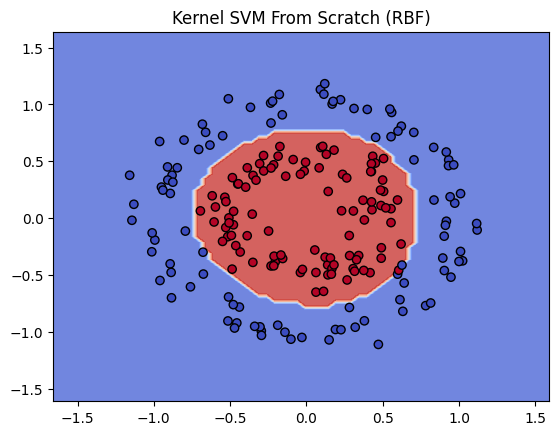

In [2]:
# --- Usage Example (The "Donut" Problem) ---
if __name__ == "__main__":
    from sklearn.datasets import make_circles
    import matplotlib.pyplot as plt

    # 1. Generate "Mixed" Data (Blue dot inside Red ring)
    X, y = make_circles(n_samples=200, noise=0.1, factor=0.5, random_state=42)
    # Convert labels from 0/1 to -1/1 for SVM math
    y = np.where(y == 0, -1, 1)

    # 2. Train
    model = KernelSVMScratch(kernel='rbf', gamma=1.0, C=1.0, learning_rate=0.01, n_iters=500)
    model.fit(X, y)

    # 3. Visualize
    print("Training Complete. Plotting...")
    
    # Meshgrid for contour plot
    h = .05
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    
    # Predict on the entire grid to draw the shape
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.coolwarm)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.coolwarm)
    plt.title("Kernel SVM From Scratch (RBF)")
    plt.show()